# 05b — Staggered-Adoption Event Study

**Project:** Causal ML for Climate Policy Effectiveness  
**Purpose:** Formal parallel-trends test and dynamic treatment-effect path, using a Sun & Abraham (2021) interaction-weighted event-study estimator  
**Input:** `data/processed/analysis_panel.csv`  
**Output:** Event-study coefficient tables and figures (per treatment type)

---

The cross-sectional DML/Causal Forest analysis in Notebook 05 identifies effects
under an unconfoundedness/overlap assumption (treatment as-good-as-random given
observed covariates). This notebook adds a complementary, genuinely dynamic
design: for each country, event time is defined relative to its **own** policy
adoption year, and effects are estimated separately by cohort x event-time
before being aggregated (Sun-Abraham), using never-treated countries as the
comparison group throughout. This avoids the "forbidden comparison" problem of
naive dynamic two-way-fixed-effects under staggered adoption (Goodman-Bacon, 2021).

The pre-treatment leads provide the paper's first formal test of the
parallel-trends assumption -- something the prior binary cross-sectional design
had no equivalent for. This replaces a prior `event_study.png`/`temporal_dynamics.csv`
that had no traceable generating code anywhere in the repository.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.event_study import run_event_study, pretrend_test
from src.visualization import set_publication_style, save_figure, COLORS

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
set_publication_style()

In [2]:
panel = pd.read_csv(PROCESSED_DIR / "analysis_panel.csv")
print(f"Panel: {panel.shape[0]:,} rows x {panel.shape[1]} columns")

OUTCOME = "log_co2"
COVARIATES = [c for c in ["population", "gdp_per_capita", "urban_pct"] if c in panel.columns]
TREATMENTS = [c for c in panel.columns if c.startswith("treat_") and panel[c].std() > 0]
print(f"Treatments: {TREATMENTS}")
print(f"Covariates: {COVARIATES}")

Panel: 7,630 rows x 74 columns
Treatments: ['treat_carbon_pricing', 'treat_renewable_mandate', 'treat_efficiency_standard']
Covariates: ['population', 'gdp_per_capita', 'urban_pct']


---
## 5b.1 — Event Study by Treatment Type

In [3]:
WINDOW = (-5, 5)
all_event_results = {}
pretrend_summary = []

for treat in TREATMENTS:
    print("=" * 60)
    print(f"Event study: {treat}")
    print("=" * 60)
    try:
        res = run_event_study(
            panel, treat, OUTCOME,
            covariate_cols=COVARIATES, window=WINDOW,
        )
        all_event_results[treat] = res
        print(res.to_string(index=False))

        pt = pretrend_test(res)
        pt["treatment"] = treat
        pretrend_summary.append(pt)
        print(f"\nPre-trend check: {pt['n_significant']}/{pt['n_pretrend_periods']} "
              f"pre-treatment leads significant (all_insignificant={pt['all_insignificant']})")

        res.to_csv(TABLE_DIR / f"event_study_{treat}.csv", index=False)
    except Exception as e:
        print(f"  FAILED: {e}")
    print()

Event study: treat_carbon_pricing


 event_time  estimate  std_error  ci_lower  ci_upper      p_value  n_cohorts
         -5  0.043545   0.041781 -0.038344  0.125434 2.973118e-01         25
         -4  0.031895   0.018006 -0.003397  0.067187 7.650640e-02         26
         -3  0.021379   0.013807 -0.005682  0.048439 1.215135e-01         27
         -2 -0.001127   0.008117 -0.017036  0.014783 8.896030e-01         28
         -1  0.000000   0.000000  0.000000  0.000000          NaN         29
          0 -0.015792   0.006600 -0.028728 -0.002856 1.672223e-02         29
          1 -0.014358   0.010384 -0.034710  0.005995 1.667816e-01         28
          2 -0.016470   0.013817 -0.043550  0.010611 2.332700e-01         27
          3 -0.035140   0.017758 -0.069945 -0.000335 4.783417e-02         26
          4 -0.058499   0.025005 -0.107509 -0.009490 1.931145e-02         26
          5 -0.302854   0.045966 -0.392945 -0.212763 4.437828e-11         26

Pre-trend check: 0/4 pre-treatment leads significant (all_insignificant=Tru

 event_time  estimate  std_error  ci_lower  ci_upper  p_value  n_cohorts
         -5  0.087748   0.045634 -0.001693  0.177190 0.054499         25
         -4  0.045784   0.016032  0.014362  0.077206 0.004293         26
         -3  0.040220   0.013801  0.013171  0.067269 0.003564         26
         -2  0.024316   0.010225  0.004274  0.044358 0.017408         26
         -1  0.000000   0.000000  0.000000  0.000000      NaN         27
          0 -0.007565   0.008120 -0.023479  0.008349 0.351464         27
          1 -0.009592   0.011844 -0.032805  0.013622 0.418019         27
          2 -0.013072   0.016171 -0.044766  0.018622 0.418880         27
          3 -0.013326   0.020281 -0.053075  0.026424 0.511147         27
          4 -0.003463   0.023454 -0.049432  0.042506 0.882617         26
          5 -0.177938   0.048877 -0.273734 -0.082141 0.000272         25

Pre-trend check: 3/4 pre-treatment leads significant (all_insignificant=False)

Event study: treat_efficiency_standard


 event_time  estimate  std_error  ci_lower  ci_upper      p_value  n_cohorts
         -5  0.077839   0.053487 -0.026993  0.182672 1.455878e-01         20
         -4  0.018336   0.016667 -0.014332  0.051004 2.712859e-01         21
         -3  0.024066   0.015221 -0.005767  0.053900 1.138599e-01         22
         -2  0.002596   0.012157 -0.021231  0.026422 8.309344e-01         23
         -1  0.000000   0.000000  0.000000  0.000000          NaN         24
          0 -0.000199   0.013816 -0.027277  0.026879 9.885006e-01         24
          1 -0.017179   0.018627 -0.053688  0.019330 3.563936e-01         24
          2 -0.034599   0.021686 -0.077104  0.007906 1.106177e-01         24
          3 -0.016559   0.030273 -0.075892  0.042774 5.843758e-01         24
          4 -0.045407   0.032493 -0.109091  0.018277 1.622720e-01         24
          5 -0.367211   0.056992 -0.478913 -0.255509 1.169621e-10         24

Pre-trend check: 0/4 pre-treatment leads significant (all_insignificant=Tru

---
## 5b.2 — Event-Study Plot (Primary Treatment: Carbon Pricing)

  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\event_study.png


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\event_study.pdf


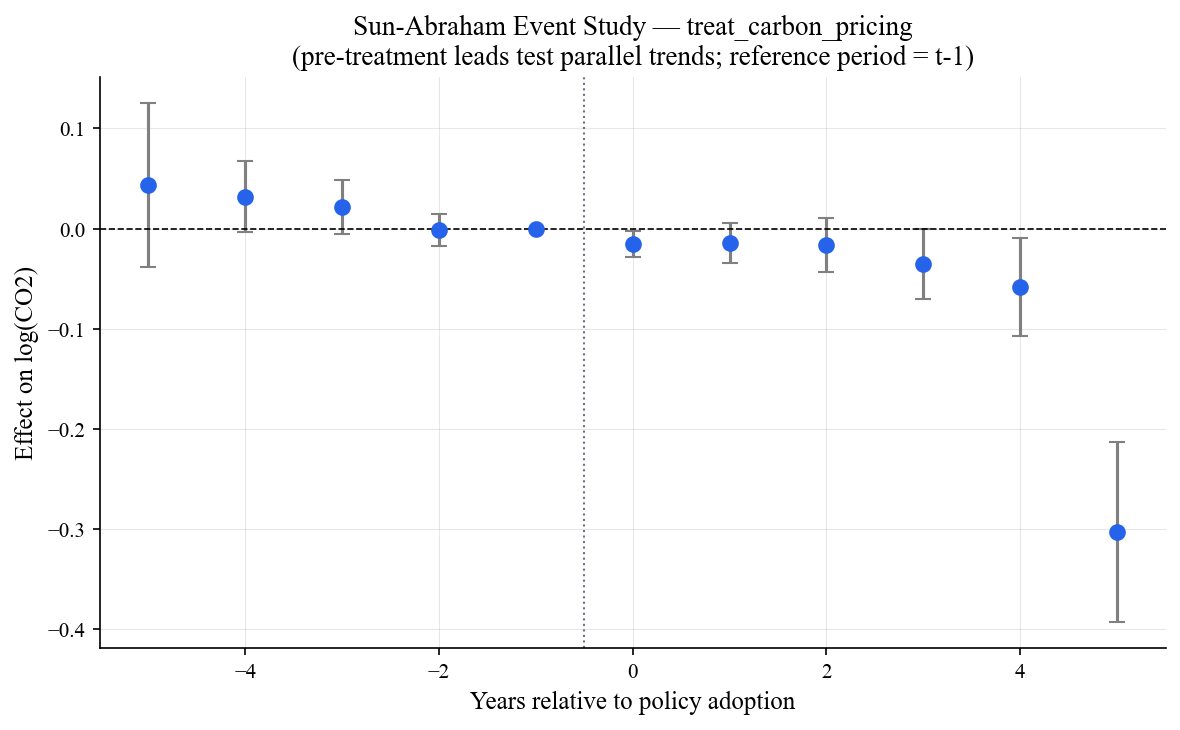

In [4]:
primary_treat = "treat_carbon_pricing" if "treat_carbon_pricing" in all_event_results else TREATMENTS[0]

if primary_treat in all_event_results:
    res = all_event_results[primary_treat]

    fig, ax = plt.subplots(figsize=(8, 5))
    colors = [COLORS["danger"] if t < 0 else COLORS["primary"] for t in res["event_time"]]
    ax.errorbar(
        res["event_time"], res["estimate"],
        yerr=[res["estimate"] - res["ci_lower"], res["ci_upper"] - res["estimate"]],
        fmt="o", capsize=4, color=COLORS["primary"], markersize=7, ecolor="gray",
    )
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.axvline(-0.5, color=COLORS["neutral"], linestyle=":", linewidth=1)
    ax.set_xlabel("Years relative to policy adoption")
    ax.set_ylabel("Effect on log(CO2)")
    ax.set_title(f"Sun-Abraham Event Study — {primary_treat}\n"
                 "(pre-treatment leads test parallel trends; reference period = t-1)")
    plt.tight_layout()
    save_figure(fig, "event_study")
    plt.show()
else:
    print("No event-study results available to plot.")

---
## 5b.3 — Cross-Check Against Cross-Sectional DML/CF Estimates

In [5]:
print("=" * 60)
print("5b.3 - Pre-trend summary and cross-check")
print("=" * 60)

pretrend_df = pd.DataFrame(pretrend_summary)
print(pretrend_df.to_string(index=False))
pretrend_df.to_csv(TABLE_DIR / "event_study_pretrend_summary.csv", index=False)

if primary_treat in all_event_results:
    res = all_event_results[primary_treat]
    post = res[res["event_time"] >= 0]
    avg_post_effect = post["estimate"].mean()
    print(f"\nAverage post-adoption event-study effect ({primary_treat}): {avg_post_effect:+.4f}")
    print("Compare to Notebook 05's DML/Causal Forest ATE for the same treatment: if signs\n"
          "disagree, this is a genuine finding about design sensitivity (unconfoundedness\n"
          "cross-section vs. own-adoption-year dynamic design) that must be discussed in the\n"
          "manuscript, not silently reconciled.")

print("\n Event study complete")
print("  Proceed to Notebook 06: Robustness Checks")

5b.3 - Pre-trend summary and cross-check
 n_pretrend_periods  n_significant  all_insignificant                 treatment
                  4              0               True      treat_carbon_pricing
                  4              3              False   treat_renewable_mandate
                  4              0               True treat_efficiency_standard

Average post-adoption event-study effect (treat_carbon_pricing): -0.0739
Compare to Notebook 05's DML/Causal Forest ATE for the same treatment: if signs
disagree, this is a genuine finding about design sensitivity (unconfoundedness
cross-section vs. own-adoption-year dynamic design) that must be discussed in the
manuscript, not silently reconciled.

 Event study complete
  Proceed to Notebook 06: Robustness Checks
